# A2 Lab 2.2: Evaluating a Classifier

This notebook begins with a provided benchmark of held-out one-second recordings. You will verify
the table, measure argmax behavior, and interpret class-specific errors. You will then apply the
same evaluation structure to the balanced local trial set collected with your board. You will not
select the Challenge operating point here.

**Learning goals**

- verify an evaluation table before trusting a metric;
- read a multi-class confusion matrix with explicit axis meaning;
- calculate and interpret one-versus-rest class metrics;
- connect a measured confusion to an application consequence.

## Notebook environment

Google Colab is the supported environment for the A2 notebooks. If this notebook is running in
Colab, the setup cell asks for the complete A2 starter ZIP, extracts it into the runtime, changes
the working directory to `Python/`, and verifies the companion files. Upload the complete ZIP when
prompted; do not upload the notebook by itself.

Local Jupyter remains usable when the notebook starts from the package's `Python/` directory.

After completing the notebook in Colab, download the executed `.ipynb` and the generated figures,
then place them in the matching locations in your local A2 package before creating the final
Canvas ZIP.

In [1]:
import io
import os
import sys
import zipfile
from pathlib import Path, PurePosixPath

IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    from google.colab import files

    package_root = Path('/content/ECE116_A2')
    python_root = package_root / 'Python'
    if not python_root.is_dir():
        print('Upload the complete ECE116 A2 starter ZIP.')
        uploaded = files.upload()
        archive_names = [name for name in uploaded if name.lower().endswith('.zip')]
        if len(archive_names) != 1:
            raise RuntimeError('Upload exactly one complete A2 starter ZIP.')

        archive_name = archive_names[0]
        with zipfile.ZipFile(io.BytesIO(uploaded[archive_name])) as archive:
            for member_name in archive.namelist():
                member_path = PurePosixPath(member_name)
                if member_path.is_absolute() or '..' in member_path.parts:
                    raise RuntimeError(f'Unsafe archive member: {member_name}')
            archive.extractall(package_root)

    if not python_root.is_dir():
        raise RuntimeError('The uploaded ZIP does not contain Python/ at its root.')
    os.chdir(python_root)
else:
    if Path.cwd().name != 'Python':
        raise RuntimeError(
            'Start the notebook from the A2 package Python/ directory, or use Google Colab.'
        )

Path('../Documentation/Fig').mkdir(parents=True, exist_ok=True)
required_files = ['eval_lib.py', 'keyword_eval.csv']
missing_files = [name for name in required_files if not Path(name).is_file()]
if missing_files:
    raise FileNotFoundError(f'Missing companion files: {missing_files}')

print('environment:', 'Google Colab' if IN_COLAB else 'Local Jupyter')
print('working directory:', Path.cwd())
print('companion files: PASS')

environment: Local Jupyter
working directory: /home/user/ECE116_A2/Python
companion files: PASS


In [2]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import eval_lib as ev

DATA = Path('.')
truth, scores, metadata = ev.load_evaluation(DATA / 'keyword_eval.csv')

print('truth shape:', truth.shape)
print('scores shape:', scores.shape)
print('label order:', ev.LABELS)
print('first clip:', metadata['clip_id'][0])
print('first true class index:', truth[0])
print('first true label:', ev.LABELS[truth[0]])
print('first score vector:', scores[0])

truth shape: (623,)
scores shape: (623, 4)
label order: ['go', 'up', 'stop', 'unknown']
first clip: go/004ae714_nohash_0.wav
first true class index: 0
first true label: go
first score vector: [0.3574446 0.3233376 0.2142826 0.1049353]


## Lab problem L5: Data integrity

One row represents one held-out one-second recording. `truth` stores one numeric true-label index
per row. `scores` stores four model scores for the same row in the released label order. Before
calculating a metric, confirm that row identity was preserved, scores have valid ranges, and each
score vector sums to approximately one.

Inspect the structures before completing the cell:

```python
print(truth.shape)                 # One true-label index per recording.
print(scores.shape)                # One four-score vector per recording.
print(metadata.keys())             # Names the available row metadata.
print(metadata['speaker_id'][:5])  # Shows that speaker IDs can repeat.
```

Several recordings can come from the same speaker. `set()` removes duplicate identifiers before
`len()` counts them:

```python
example_speakers = ['speaker_a', 'speaker_a', 'speaker_b']
len(example_speakers)       # 3 recordings
len(set(example_speakers))  # 2 speakers
```

Use these directly transferable patterns for L5a-L5f:

```python
len(truth)
len(set(metadata['clip_id']))
len(set(metadata['speaker_id']))
bool(np.all((scores >= 0.0) & (scores <= 1.0)))
float(score_vector_sums.min())
float(score_vector_sums.max())
```

The work in this problem is connecting each check to the integrity claim it supports, then
confirming that the observed values satisfy the assertions.

In [3]:
number_of_rows = len(truth)                # L5a: count the held-out examples in truth.
number_of_unique_clip_ids = len(set(metadata['clip_id']))     # L5b: count distinct clip IDs.
number_of_unique_speakers = len(set(metadata['speaker_id']))  # L5c: count distinct speaker IDs.
scores_are_in_unit_interval = bool(np.all((scores >= 0.0) & (scores <= 1.0)))  # L5d: every score is from 0 through 1.
score_vector_sums = scores.sum(axis=1)     # Sums the four class scores separately for every clip.
minimum_score_sum = float(score_vector_sums.min())  # L5e: smallest per-clip score sum.
maximum_score_sum = float(score_vector_sums.max())  # L5f: largest per-clip score sum.


class_counts = {
    label: int(np.sum(truth == class_index))
    for class_index, label in enumerate(ev.LABELS)
}

print('rows:', number_of_rows)
print('unique_clips:', number_of_unique_clip_ids)
print('unique_speakers:', number_of_unique_speakers)
print('class_counts:', class_counts)
print('scores_in_unit_interval:', scores_are_in_unit_interval)
print('score_sum_min:', minimum_score_sum)
print('score_sum_max:', maximum_score_sum)

assert number_of_rows == number_of_unique_clip_ids
assert scores_are_in_unit_interval
assert abs(minimum_score_sum - 1.0) < 1e-4
assert abs(maximum_score_sum - 1.0) < 1e-4

rows: 623
unique_clips: 623
unique_speakers: 236
class_counts: {'go': 154, 'up': 164, 'stop': 149, 'unknown': 156}
scores_in_unit_interval: True
score_sum_min: 0.9999997999999999
score_sum_max: 1.0000002000000001


## Lab problem L6: Argmax behavior

Argmax converts each score vector into the index of its largest score. A confusion matrix then
counts each `(true class, predicted class)` pair. Rows are true labels and columns are predicted
labels. Overall accuracy summarizes the diagonal, but it does not show which mistakes occurred.

For three toy examples:

```text
true label:      go   up   go
predicted label: go   go   unknown
```

the matrix receives one count at `(go, go)`, one at `(up, go)`, and one at `(go, unknown)`.
Apply the same operation to every benchmark row with these patterns:

```python
predicted_class_indices = np.argmax(scores, axis=1)
matrix[true_class_index, predicted_class_index] += 1
accuracy = np.trace(matrix) / matrix.sum()
```

`axis=1` selects one largest class score within each recording. The matrix increment preserves
the meaning that rows are true labels and columns are predicted labels.

argmax accuracy: 0.8363
[[123   6   4  21]
 [ 10 136  10   8]
 [  1   7 139   2]
 [ 19  11   3 123]]


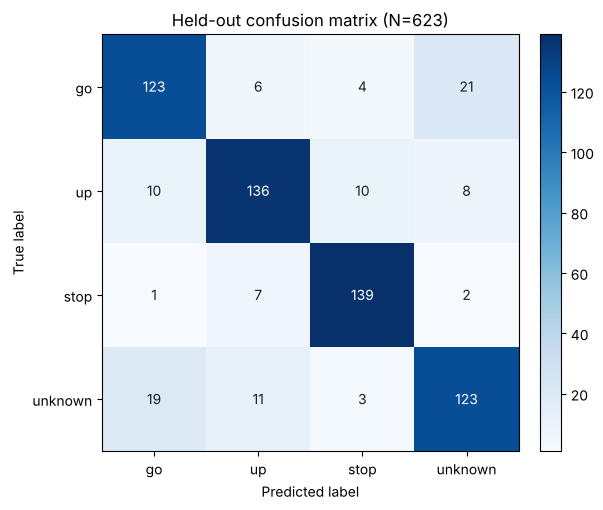

In [4]:
predicted_class_indices = np.argmax(scores, axis=1)  # L6a: argmax class index for every score vector.
matrix = np.zeros((len(ev.LABELS), len(ev.LABELS)), dtype=np.int64)
for true_class_index, predicted_class_index in zip(truth, predicted_class_indices):
    matrix[true_class_index, predicted_class_index] += 1  # L6b: count this measured outcome.
accuracy = np.trace(matrix) / matrix.sum()  # L6c: diagonal count divided by the complete matrix count.


print('argmax accuracy:', round(float(accuracy), 4))
print(matrix)
assert matrix.sum() == len(truth)

fig, ax = plt.subplots(figsize=(6.4, 5.2))
image = ax.imshow(matrix, cmap='Blues')
ax.set_xticks(range(len(ev.LABELS)), ev.LABELS)
ax.set_yticks(range(len(ev.LABELS)), ev.LABELS)
ax.set_xlabel('Predicted label')
ax.set_ylabel('True label')
ax.set_title(f'Held-out confusion matrix (N={matrix.sum()})')
for row in range(len(ev.LABELS)):
    for column in range(len(ev.LABELS)):
        text_color = 'white' if matrix[row, column] > matrix.max() / 2 else '#17202a'
        ax.text(column, row, str(matrix[row, column]), ha='center', va='center', color=text_color)
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
fig.savefig('../Documentation/Fig/a2_confusion.png', dpi=180)
plt.show()

## Lab problem L7: One-versus-rest class metrics

For one selected class, the diagonal cell is a true positive. The rest of its prediction column
contains false positives, and the rest of its true-label row contains false negatives. Every cell
outside that row and column is a true negative. Repeat the same accounting once for each class.

For the class at `class_index`, use the following matrix regions:

```python
true_positive = int(matrix[class_index, class_index])
false_positive = int(matrix[:, class_index].sum() - true_positive)
false_negative = int(matrix[class_index, :].sum() - true_positive)
true_negative = int(
    matrix.sum() - true_positive - false_positive - false_negative
)
```

The selected prediction column contains every example predicted as the class, so removing the
diagonal leaves false positives. The selected true-label row contains every real example of the
class, so removing the diagonal leaves false negatives.

Use the supplied `divide_or_zero()` helper with the formulas printed in the handout. The task is
to connect each formula to the physical consequence of a false or missed timer command, not to
discover NumPy slicing syntax.

In [5]:
def divide_or_zero(numerator, denominator):
    return numerator / denominator if denominator else 0.0

metrics = []
for class_index, label in enumerate(ev.LABELS):

    true_positive = int(matrix[class_index, class_index])  # L7a: the selected class's diagonal cell.
    false_positive = int(matrix[:, class_index].sum() - true_positive)  # L7b: prediction column minus the diagonal.
    false_negative = int(matrix[class_index, :].sum() - true_positive)  # L7c: true-label row minus the diagonal.
    true_negative = int(
        matrix.sum() - true_positive - false_positive - false_negative
    )  # L7d: every cell outside the selected row and column.

    precision = divide_or_zero(true_positive, true_positive + false_positive)    # L7e: TP / (TP + FP).
    recall = divide_or_zero(true_positive, true_positive + false_negative)       # L7f: TP / (TP + FN).
    specificity = divide_or_zero(true_negative, true_negative + false_positive)  # L7g: TN / (TN + FP).
    f1 = divide_or_zero(2 * precision * recall, precision + recall)              # L7h: harmonic mean of precision and recall.


    assert true_positive + false_negative == int(matrix[class_index, :].sum())
    assert true_positive + false_positive == int(matrix[:, class_index].sum())
    assert true_positive + false_positive + false_negative + true_negative == int(matrix.sum())

    metrics.append({
        'label': label,
        'precision': precision,
        'recall': recall,
        'specificity': specificity,
        'f1': f1,
    })

print(f"{'label':<10} {'precision':>10} {'recall':>10} {'specificity':>12} {'F1':>8}")
for row in metrics:
    print(f"{row['label']:<10} {row['precision']:>10.3f} {row['recall']:>10.3f} "
          f"{row['specificity']:>12.3f} {row['f1']:>8.3f}")

label       precision     recall  specificity       F1
go              0.804      0.799        0.936    0.801
up              0.850      0.829        0.948    0.840
stop            0.891      0.933        0.964    0.911
unknown         0.799      0.788        0.934    0.794


### Interpretation

Name one observed confusion that matters for a timer. Identify the true class, predicted class,
and matrix count. Explain the physical consequence. Distinguish a missed command, which asks the
user to repeat, from a false accepted command, which changes timer state without intent.

**Measured confusion:** 19 of the 156 true `unknown` recordings were predicted as `go`, the
(true `unknown`, predicted `go`) cell. In the timer, each of these is a false accepted command: a
non-command word would commit the accumulated time and start the countdown without the user's
intent. This differs from the 21 true `go` recordings predicted as `unknown`, the (true `go`,
predicted `unknown`) cell. Those are missed commands, which leave the timer unchanged and only ask
the user to repeat the word. `go` precision is 0.804, so about one in five argmax `go` predictions
on this benchmark is not a real `go`.

## Lab problem L8: Evaluate your local trials

Each `TRIAL_RESULT` line is one labeled, one-second example in the same basic form as one benchmark
row: a true label and one four-score model output. Load the complete 40-trial log, confirm that it
contains 10 examples from each class, and summarize it with a separate confusion matrix.

local_rows: 40
local_class_counts: {'go': 10, 'up': 10, 'stop': 10, 'unknown': 10}
local_argmax_accuracy: 0.575
[[10  0  0  0]
 [ 6  3  1  0]
 [ 1  0  9  0]
 [ 6  1  2  1]]


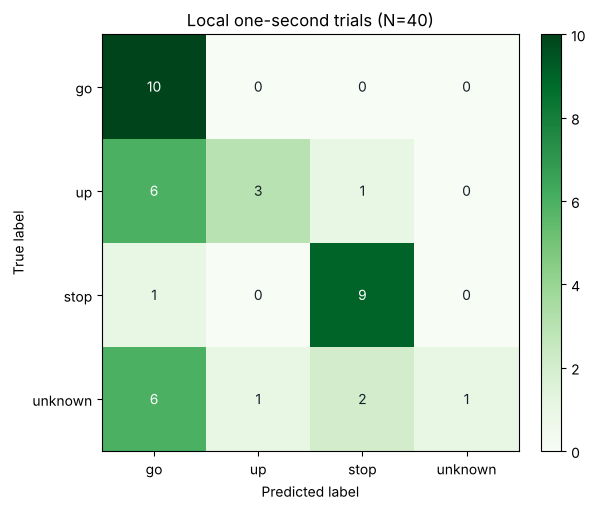

In [6]:
local_truth, local_scores, local_metadata = ev.load_local_trials(
    Path('../Documentation/a2_local_trials.txt')
)
local_predictions = np.argmax(local_scores, axis=1)
local_matrix = np.zeros((len(ev.LABELS), len(ev.LABELS)), dtype=np.int64)
for true_class_index, predicted_class_index in zip(local_truth, local_predictions):
    local_matrix[true_class_index, predicted_class_index] += 1

local_class_counts = {
    label: int(np.sum(local_truth == class_index))
    for class_index, label in enumerate(ev.LABELS)
}
local_accuracy = np.trace(local_matrix) / local_matrix.sum()

print('local_rows:', len(local_truth))
print('local_class_counts:', local_class_counts)
print('local_argmax_accuracy:', round(float(local_accuracy), 4))
print(local_matrix)

assert len(local_truth) == 40
assert all(count == 10 for count in local_class_counts.values())

fig, ax = plt.subplots(figsize=(6.4, 5.2))
image = ax.imshow(local_matrix, cmap='Greens')
ax.set_xticks(range(len(ev.LABELS)), ev.LABELS)
ax.set_yticks(range(len(ev.LABELS)), ev.LABELS)
ax.set_xlabel('Predicted label')
ax.set_ylabel('True label')
ax.set_title('Local one-second trials (N=40)')
for row in range(len(ev.LABELS)):
    for column in range(len(ev.LABELS)):
        text_color = 'white' if local_matrix[row, column] > max(local_matrix.max() / 2, 1) else '#17202a'
        ax.text(column, row, str(local_matrix[row, column]), ha='center', va='center', color=text_color)
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
fig.savefig('../Documentation/Fig/a2_local_confusion.png', dpi=180)
plt.show()

**Local-validation response:** One speaker (me) recorded 40 one-second trials in a single
session through the XIAO ESP32-S3 Sense onboard microphone, about 25 cm from the board, in a room
with some background noise. The set has 10 trials per class. The non-command words for the 10
`unknown` trials were not written down during collection. Argmax accuracy on this set is 0.575
(23 of 40).

The clearest local pattern is over-prediction of `go`. All 10 true `go` trials were predicted as
`go`, but 13 of the 30 other trials were also predicted as `go`: 6 of 10 `up`, 6 of 10 `unknown`,
and 1 of 10 `stop`. On the benchmark the same cells are much smaller: 10 of 164 `up` and 19 of 156
`unknown` recordings were predicted as `go`. `stop` behaved similarly in both sets (9 of 10
locally, 139 of 149 on the benchmark).

These 40 trials describe one speaker, one room, one distance, and one session. They do not
estimate general model accuracy. With 10 trials per class, one trial changes a class rate by 10
percentage points. The comparison shows that this model can behave very differently under these
local conditions than on the held-out corpus. It does not show why, which could be the microphone,
the room noise, the speaking style, or the timing of each word inside the window.

## What transfers to the Challenge

Keep the benchmark integrity report, both confusion figures, class metrics, consequence analysis,
and complete local trial log. In the Challenge notebook, you will apply a supplied operating
requirement to the larger benchmark and use a threshold sweep to choose a policy. The Lab does not
provide the resulting threshold.